# BÀI TẬP LỚN: XẤP XỈ HÀM SỐ DÙNG MẠNG MLP BẰNG PYTORCH

## 1. Import thư viện

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
import copy
import json
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
from datetime import datetime
from torch.utils.data import TensorDataset, DataLoader
from torchviz import make_dot
from matplotlib.patches import Circle
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

### QUẢN LÝ KẾT QUẢ THỰC NGHIỆM VÀ THIẾT LẬP MÔI TRƯỜNG HUẤN LUYỆN

In [ ]:
# Tao thu muc rieng cho moi lan chay
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = Path("mlp_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
LOG_DIR = OUTPUT_DIR / "logs"

for folder in [CHECKPOINT_DIR, FIGURE_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "training_log.txt"

# Ghi log
def log_message(message):
    print(message)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(str(message) + "\n")

# Luu trong so mo hinh
def save_checkpoint(state_dict, filename, metadata=None):
    payload = {
        "model_state_dict": {
            k: v.detach().cpu().clone()
            for k, v in state_dict.items()
        },
        "metadata": metadata or {},
        "run_id": RUN_ID
    }
    torch.save(payload, CHECKPOINT_DIR / filename)

# Luu lich su huan luyen
def save_history(results, experiment_name):
    histories = []
    for item in results:
        row = {
            k: v for k, v in item.items()
            if k not in ["model", "best_weights"]
        }
        histories.append(row)

    with open(LOG_DIR / f"{experiment_name}_history.json",
              "w", encoding="utf-8") as f:
        json.dump(histories, f, ensure_ascii=False, indent=2)

# Lưu biểu đồ
def save_figure(filename):
    plt.savefig(
        FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

# Xác định thiết bị huấn luyện
device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)
print(f"Sử dụng thiết bị: {device}")

# Ghi log
log_message(f"Bat dau chay: {RUN_ID}")
log_message(f"Thiet bi: {device}")

Sử dụng thiết bị: cpu
Bat dau chay: 20261102_152659
Thiet bi: cpu


**Nhận xét**

- Mỗi lần chạy chương trình sẽ tạo một thư mục riêng dựa trên thời gian thực hiện, giúp phân biệt và quản lý kết quả của từng lần thử nghiệm.
- Các trọng số mô hình, lịch sử huấn luyện, biểu đồ và thông tin quá trình chạy được lưu thành các tệp riêng biệt.
- Thiết bị huấn luyện được lựa chọn tự động dựa trên khả năng hỗ trợ GPU của hệ thống.
- Việc lưu trữ kết quả giúp thuận tiện cho việc theo dõi, so sánh và đánh giá các thí nghiệm MLP.

### THIẾT LẬP RANDOM SEED VÀ ĐẢM BẢO TÍNH TÁI LẬP

In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Tăng tính tái lập; có thể làm chậm một chút trên GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Ba seed dưới đây dùng cho các lần khởi tạo và huấn luyện mô hình.
SEEDS = [42,  123, 2026]
print("Các Random Seeds:", SEEDS)

Các Random Seeds: [42, 123, 2026]


Nhận xét về thiết lập Random Seed
- Thiết lập Random Seed giúp các thao tác ngẫu nhiên trong quá trình chạy chương trình có tính tái lập.
- Các thư viện random, NumPy và PyTorch được thiết lập cùng một giá trị Seed để hạn chế sự khác biệt giữa các lần chạy.
- Điều này hỗ trợ quá trình thử nghiệm và so sánh kết quả mô hình MLP một cách nhất quán hơn.
Bổ sung về seed thực nghiệm: Dữ liệu train/validation/test được sinh cố định bằng các seed dữ liệu riêng (42, 44, 43). Mỗi cấu hình MLP được huấn luyện độc lập với ba seed mô hình [42, 123, 2026]. Kết quả từng lần chạy được lưu riêng; cấu hình được chọn theo Validation MSE trung bình. Tập Test chỉ được sử dụng sau khi chọn cấu hình.

## DATASET

In [ ]:
# DATASET
os.makedirs("./data", exist_ok=True)

def gaussian_2d(x1, x2, mu, C_inv, det_C):
    diff = np.stack([x1 - mu[0], x2 - mu[1]], axis=-1)
    quad_term = np.sum(np.dot(diff, C_inv) * diff, axis=-1)
    coeff = 1.0 / (2 * np.pi * np.sqrt(det_C))
    return coeff * np.exp(-0.5 * quad_term)


# Generate data
def generate_data(n, r1, r2, m, c, seed=42, export_path=None, verbose=1):
    np.random.seed(seed)

    det_c = np.linalg.det(c)
    c_inv = np.linalg.inv(c)

    x1 = np.random.uniform(r1[0], r1[1], n)
    x2 = np.random.uniform(r2[0], r2[1], n)
    y = gaussian_2d(x1, x2, m, c_inv, det_c)

    x = np.stack([x1, x2], axis=-1)

    if export_path:
        df = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y})
        df.to_csv(export_path, index=False)

    if verbose:
        print(f"x1:  {x1[0]} {x1[-1]}")
        print(f"x2:  {x2[0]} {x2[-1]}")
        print(f"x shape: {x.shape}")
        print(f"y:  {y[0]} {y[-1]}")
        print(f"y shape: {y.shape}")

    return x, y


# Thông số phân phối Gaussian
rangex1 = (-2, 2)
rangex2 = (-4, 4)
mean = np.array([0.0, 0.0])
cov = np.array([[0.3, -0.5], [-0.5, 2.0]])


# Sinh và lưu các tập dữ liệu với Random Seed riêng biệt

# Training dataset: 20,000 mẫu - Seed 42
x_train, y_train = generate_data(
    n=20000, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=42, export_path="./data/train.csv", verbose=1
)

# Testing dataset: 100 mẫu - Seed 43
x_test, y_test = generate_data(
    n=100, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=43, export_path="./data/test.csv", verbose=1
)

# Validation dataset: 100 mẫu - Seed 44
x_valid, y_valid = generate_data(
    n=100, r1=rangex1, r2=rangex2, m=mean, c=cov,
    seed=44, export_path="./data/valid.csv", verbose=1
)

x1:  -0.50183952461055 -1.3109407425768471
x2:  1.839986487919763 -0.10061041219637534
x shape: (20000, 2)
y:  0.11482386421803446 0.0016353276009709308
y shape: (20000,)
x1:  -1.5397817344408842 0.4677479032835805
x2:  -3.1731799129747644 3.707912990236645
x shape: (100, 2)
y:  3.822474576172641e-09 3.336479139651754e-05
y shape: (100,)
x1:  1.3393685946625977 0.9647761303303466
x2:  -3.2086987967130494 -0.10799034279873876
x shape: (100, 2)
y:  0.008992094160521933 0.02174145174246771
y shape: (100,)


**Nhận xét về cách chia dữ liệu và Random Seed**

- Bộ dữ liệu được tạo thành 3 tập riêng biệt, bao gồm $20.000$ mẫu $Training$, 100 mẫu $Validation$ và 100 mẫu $Testing$.
- Các mẫu đầu vào $x_1$ và $x_2$ được sinh ngẫu nhiên theo phân phối $Uniform$ trong phạm vi lần lượt là $[-2, 2]$ và $[-4, 4]$. Giá trị đầu ra $y$ được tính từ hàm $Gaussian$ hai chiều.
- Sử dụng $Random\ Seed = 42$ cho tập Training, $43$ cho tập $Testing$ và $44$ cho tập $Validation$ nhằm đảm bảo khả năng tái lập dữ liệu và tránh trùng lặp giữa các tập.
- Tập Training được sử dụng để huấn luyện mô hình $MLP$, tập $Validation$ dùng để theo dõi và lựa chọn mô hình phù hợp, còn tập Testing được sử dụng để đánh giá kết quả cuối cùng.

### Load Data

In [ ]:
def load_dataset(csv_train, csv_valid, csv_test):
    df_train = pd.read_csv(csv_train)
    df_valid = pd.read_csv(csv_valid)
    df_test = pd.read_csv(csv_test)

    x_train = df_train[['x1', 'x2']].values.astype(np.float32)
    y_train = df_train['y'].values.astype(np.float32)

    x_valid = df_valid[['x1', 'x2']].values.astype(np.float32)
    y_valid = df_valid['y'].values.astype(np.float32)

    x_test = df_test[['x1', 'x2']].values.astype(np.float32)
    y_test = df_test['y'].values.astype(np.float32)

    return x_train, y_train, x_valid, y_valid, x_test, y_test

x_train, y_train, x_valid, y_valid, x_test, y_test = load_dataset(
    csv_train="./data/train.csv",
    csv_valid="./data/valid.csv",
    csv_test="./data/test.csv"
)

### Visualize dataset

### Thống kê mô tả

In [ ]:
# THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS)

# Chuyển dữ liệu thành DataFrame
df_train = pd.DataFrame({
    'x1': x_train[:, 0],
    'x2': x_train[:, 1],
    'y': y_train.reshape(-1)
})

df_valid = pd.DataFrame({
    'x1': x_valid[:, 0],
    'x2': x_valid[:, 1],
    'y': y_valid.reshape(-1)
})

df_test = pd.DataFrame({
    'x1': x_test[:, 0],
    'x2': x_test[:, 1],
    'y': y_test.reshape(-1)
})

In [ ]:
# Descriptive Statistics - Training Dataset

print("========== TRAINING DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_train.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_train.corr().round(4))

========== TRAINING DATASET ==========

Descriptive Statistics:
                 x1            x2             y
count  20000.000000  20000.000000  20000.000000
mean      -0.002621     -0.004945      0.031551
std        1.154010      2.303040      0.056982
min       -1.999954     -3.999956      0.000000
25%       -1.000453     -1.996352      0.000075
50%       -0.004273      0.008489      0.003596
75%        0.996564      1.968934      0.032657
max        1.999699      3.999208      0.268928

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.0154 -0.0005
x2 -0.0154  1.0000  0.0001
y  -0.0005  0.0001  1.0000


In [ ]:
# Descriptive Statistics - Validation Dataset

print("========== VALIDATION DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_valid.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_valid.corr().round(4))

========== VALIDATION DATASET ==========

Descriptive Statistics:
               x1          x2           y
count  100.000000  100.000000  100.000000
mean     0.024931   -0.090614    0.033736
std      1.194095    2.132450    0.057241
min     -1.936569   -3.997090    0.000000
25%     -1.132479   -1.522695    0.000128
50%      0.025985   -0.119899    0.003568
75%      0.999294    1.607376    0.039130
max      1.963291    3.892176    0.237495

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.1189  0.0120
x2 -0.1189  1.0000  0.0026
y   0.0120  0.0026  1.0000


In [ ]:
# Descriptive Statistics - Testing Dataset

print("========== TESTING DATASET ==========")

# Thống kê mô tả
print("\nDescriptive Statistics:")
print(df_test.describe().round(6))

# Ma trận tương quan
print("\nCorrelation Matrix:")
print(df_test.corr().round(4))

========== TESTING DATASET ==========

Descriptive Statistics:
               x1          x2           y
count  100.000000  100.000000  100.000000
mean     0.070133    0.101263    0.026771
std      1.171134    2.470897    0.052547
min     -1.979667   -3.982083    0.000000
25%     -0.958039   -2.279633    0.000045
50%      0.130580   -0.029815    0.002175
75%      0.967362    2.251523    0.020124
max      1.994793    3.989748    0.250900

Correlation Matrix:
        x1      x2       y
x1  1.0000 -0.0035 -0.0120
x2 -0.0035  1.0000  0.0063
y  -0.0120  0.0063  1.0000


### Trực quan hóa dữ liệu


Training samples: 20000 -- Shape: (20000, 2) (20000,)
Validating samples: 100 -- Shape: (100, 2) (100,)
Testing samples: 100 -- Shape: (100, 2) (100,)


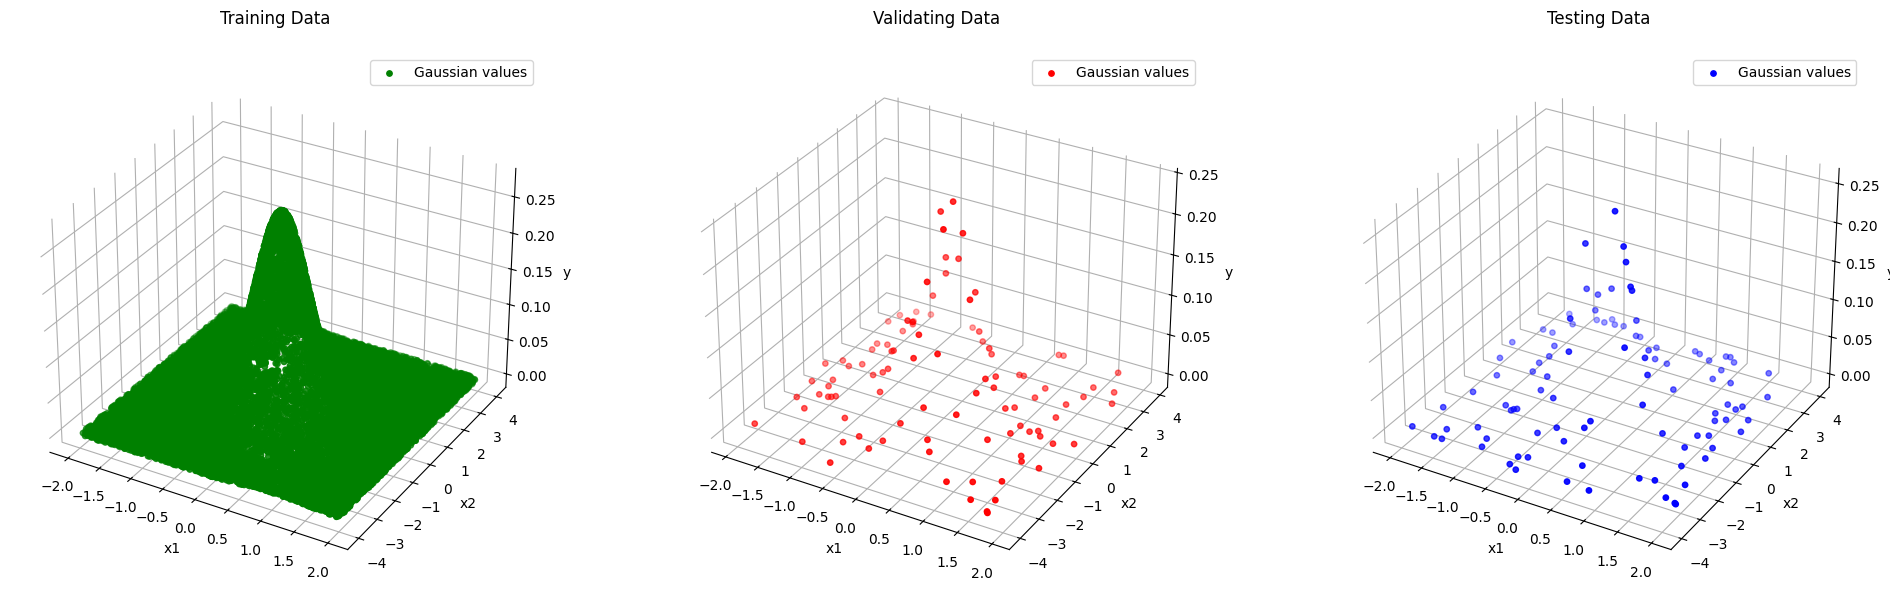

In [ ]:
# TRỰC QUAN HÓA TẬP DỮ LIỆU
def visualize_dataset(x, y, color, title, ax):
    ax.scatter(
        x[:, 0], x[:, 1], y,
        c=color,
        marker='o',
        s=15,
        label="Gaussian values"
    )

    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('y')
    ax.legend(loc='upper right')

    # Không gian bên ngoài màu trắng tinh
    ax.set_facecolor("#FFFFFF")

    ax.xaxis.set_pane_color((1, 1, 1, 1))
    ax.yaxis.set_pane_color((1, 1, 1, 1))
    ax.zaxis.set_pane_color((1, 1, 1, 1))

    # Đường lưới màu trắng
    ax.grid(True, color="#FFFFFF", linewidth=0.8)


print(f"\nTraining samples: {len(x_train)} -- Shape: {x_train.shape} {y_train.shape}")
print(f"Validating samples: {len(x_valid)} -- Shape: {x_valid.shape} {y_valid.shape}")
print(f"Testing samples: {len(x_test)} -- Shape: {x_test.shape} {y_test.shape}")

fig = plt.figure(figsize=(20, 6))

ax1 = fig.add_subplot(1, 3, 1, projection='3d')
visualize_dataset(
    x_train, y_train,
    color="green",
    title="Training Data\n",
    ax=ax1
)

ax2 = fig.add_subplot(1, 3, 2, projection='3d')
visualize_dataset(
    x_valid, y_valid,
    color="red",
    title="Validating Data\n",
    ax=ax2
)

ax3 = fig.add_subplot(1, 3, 3, projection='3d')
visualize_dataset(
    x_test, y_test,
    color="blue",
    title="Testing Data\n",
    ax=ax3
)

plt.tight_layout()

save_figure("dataset_visualization.png")
plt.show()

**Nhận xét:**
- Bộ dữ liệu gồm 20.000 mẫu huấn luyện, 100 mẫu validation và 100 mẫu test; mỗi mẫu có hai đầu vào $x1$, $x2$ và một giá trị mục tiêu y.
- Ba tập dữ liệu được biểu diễn bằng biểu đồ phân tán 3D, cho thấy sự phân bố của các điểm dữ liệu theo hai biến đầu vào và giá trị $y$.
- Số lượng mẫu $Validation$ và test nhỏ hơn nhiều so với tập train, vì vậy kết quả đánh giá có thể chưa phản ánh đầy đủ mọi trường hợp của dữ liệu.


### VẼ BỀ MẶT HÀM GAUSSIAN THẬT

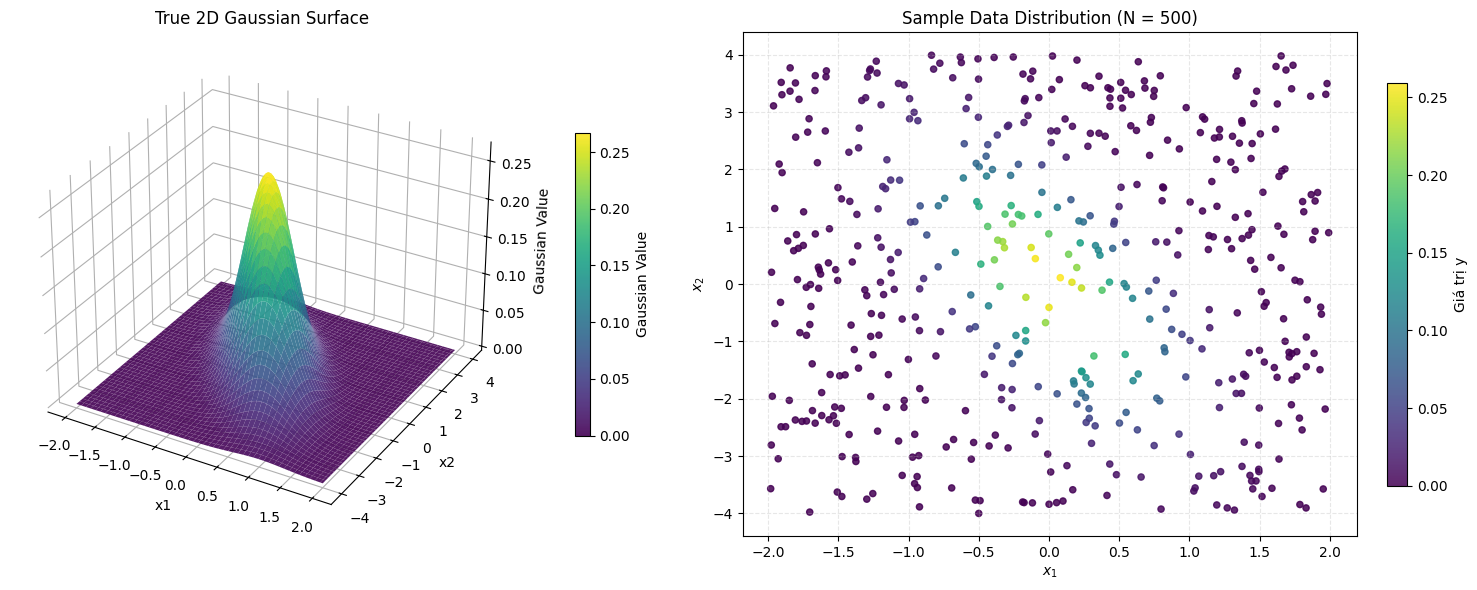

In [ ]:
# Tạo lưới tọa độ đầu vào
x1_grid = np.linspace(rangex1[0], rangex1[1], 100)
x2_grid = np.linspace(rangex2[0], rangex2[1], 100)

X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Tính các tham số của phân phối Gaussian
det_cov = np.linalg.det(cov)
cov_inv = np.linalg.inv(cov)

# Tính giá trị Gaussian thật tại từng điểm trên lưới
Y_true = gaussian_2d(
    X1, X2, mean, cov_inv, det_cov
)

# Tạo Figure gồm 2 biểu đồ nằm cạnh nhau
fig = plt.figure(figsize=(16, 6))

# ==========================================
# 1. VẼ BỀ MẶT GAUSSIAN 3D
# ==========================================

ax1 = fig.add_subplot(1, 2, 1, projection='3d')

surface = ax1.plot_surface(
    X1, X2, Y_true,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax1.set_title("True 2D Gaussian Surface")
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_zlabel("Gaussian Value")

# Thiết lập nền màu trắng
ax1.set_facecolor("#FFFFFF")

ax1.xaxis.set_pane_color((1, 1, 1, 1))
ax1.yaxis.set_pane_color((1, 1, 1, 1))
ax1.zaxis.set_pane_color((1, 1, 1, 1))

ax1.grid(True, color="#FFFFFF", linewidth=0.8)

# Thanh màu Gaussian 3D
fig.colorbar(
    surface, ax=ax1,
    shrink=0.6,
    pad=0.08,
    label="Gaussian Value"
)

# ==========================================
# 2. VẼ PHÂN BỐ TẬP DỮ LIỆU MẪU 2D
# ==========================================

# Lấy ngẫu nhiên 500 mẫu từ tập Training
N = 500
rng = np.random.default_rng(42)

indices = rng.choice(
    len(x_train), N, replace=False
)

x1_sample = x_train[indices, 0]
x2_sample = x_train[indices, 1]
y_sample = y_train.reshape(-1)[indices]

# Vẽ biểu đồ phân bố dữ liệu
ax2 = fig.add_subplot(1, 2, 2)

scatter = ax2.scatter(
    x1_sample,
    x2_sample,
    c=y_sample,
    cmap='viridis',
    s=20,
    alpha=0.85
)

ax2.set_title(f"Sample Data Distribution (N = {N})")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")

# Thanh màu thể hiện giá trị Gaussian
fig.colorbar(
    scatter, ax=ax2,
    shrink=0.8,
    pad=0.04,
    label="Giá trị y"
)

ax2.grid(True, linestyle='--', alpha=0.3)

# ==========================================
# HIỂN THỊ VÀ LƯU HÌNH
# ==========================================

plt.tight_layout()

save_figure("gaussian_surface_and_sample_distribution.png")

plt.show()

**Nhận xét về bề mặt hàm Gaussian thật**

- Bề mặt hàm $Gaussian$ được biểu diễn dưới dạng một mặt cong $3D$ liên tục, có hình dạng giống một chiếc chuông.
- Giá trị $Gaussian$ đạt mức cao nhất tại vùng trung tâm và giảm dần khi khoảng cách đến tâm phân phối tăng lên.
- Bề mặt thể hiện đặc trưng của phân phối $Gaussian$ hai chiều, với sự thay đổi giá trị theo hai trục tọa độ $x_1$ và $x_2$.
- Đây là cơ sở để đối chiếu kết quả dự đoán của mô hình $MLP$ với giá trị thực tế của hàm $Gaussian$.

### Normalize Data (MinMaxScaler)

In [ ]:
class MinMaxScalerCustom:
    def __init__(self):
        self.min_val = None
        self.max_val = None

    def fit_transform(self, x):
        self.min_val = np.min(x, axis=0, keepdims=True)
        self.max_val = np.max(x, axis=0, keepdims=True)
        return (x - self.min_val) / (self.max_val - self.min_val + 1e-8)

    def transform(self, x):
        return (x - self.min_val) / (self.max_val - self.min_val + 1e-8)

scaler_x = MinMaxScalerCustom()
x_train_norm = scaler_x.fit_transform(x_train)
x_valid_norm = scaler_x.transform(x_valid)
x_test_norm = scaler_x.transform(x_test)

**Nhận xét:**
- Dữ liệu đầu vào $x1$ và $x2$ được chuẩn hóa bằng phương pháp $Min$ $Max$ $Scaler$ về khoảng giá trị gần từ 0 đến 1.
- Các giá trị min và max được xác định từ tập train rồi sử dụng để chuẩn hóa tập $Validation$ và test, giúp thống nhất thang đo giữa các tập.
- Việc chuẩn hóa giúp mô hình $MLP$ xử lý dữ liệu đầu vào thuận lợi hơn trong quá trình huấn luyện.